# University of Kigali
**Student:** Gervais Rutikanga  
**Registration Number:** 26016700  
**Program:** Master of Science in Information Technology  
**Module:** MIT 91205 – Big Data Analytics  
**Practical:** Aggregation in MapReduce

## Overview
This notebook implements a local Python simulation of MapReduce aggregation on the Sample Superstore dataset. It simulates 8 logical mappers and 4 logical reducers and compares no combiner, conventional combiner, and in-mapper combining. It measures shuffle records, JSON-serialized shuffle bytes, runtime, reducer load, key skew, and scalability. Outputs are validated against Pandas `groupby`.

**Scope:** This is a Python simulation, not a Hadoop/Spark cluster deployment. Serialized shuffle bytes are not actual network traffic.

### Imports and setup

In [1]:
import csv, time, zlib, json, math, collections, statistics
import pandas as pd
import matplotlib.pyplot as plt

NUM_MAPPERS, NUM_REDUCERS = 8, 4
REPEATS = 10
CSV = "Sample - Superstore.csv"
plt.rcParams.update({"font.size": 9})

## Load the data

In [2]:
def load_dataset(path=CSV):
    with open(path, encoding="latin-1", newline="") as f:
        return list(csv.DictReader(f))

rows = load_dataset()
print(f"Loaded {len(rows):,} records from {CSV!r}.")

Loaded 9,994 records from 'Sample - Superstore.csv'.


## read data

In [3]:
dataset_df = pd.read_csv(CSV, encoding="latin-1")
required = ["Category", "Region", "Sub-Category", "State", "Customer ID",
            "Sales", "Profit", "Quantity"]
missing_columns = sorted(set(required) - set(dataset_df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

quality_report = pd.DataFrame({
    "Metric": ["Records", "Columns", "Missing cells", "Duplicate rows",
               "Distinct categories", "Distinct regions", "Distinct states"],
    "Value": [len(dataset_df), len(dataset_df.columns),
              int(dataset_df.isna().sum().sum()), int(dataset_df.duplicated().sum()),
              dataset_df.Category.nunique(), dataset_df.Region.nunique(),
              dataset_df.State.nunique()]
})
display(quality_report)

for col in ["Sales", "Profit", "Quantity"]:
    dataset_df[col] = pd.to_numeric(dataset_df[col], errors="coerce")
invalid = dataset_df[["Sales", "Profit", "Quantity"]].isna().sum()
display(invalid.rename("Invalid_or_missing_numeric_values").to_frame())
if invalid.sum():
    raise ValueError("Numeric aggregation columns contain missing or invalid values.")
assert len(rows) == len(dataset_df)

,Metric,Value
0,Records,9994
1,Columns,21
2,Missing cells,0
3,Duplicate rows,0
4,Distinct categories,3
5,Distinct regions,4
6,Distinct states,49


,Invalid_or_missing_numeric_values
Sales,0
Profit,0
Quantity,0


## Map, combine and partition functions

In [4]:
def splits(data, n):
    q, r = divmod(len(data), n)
    out, start = [], 0
    for i in range(n):
        size = q + (i < r)
        out.append(data[start:start + size])
        start += size
    return out

def mapper(row, key):
    yield row[key], (float(row["Sales"]), float(row["Profit"]), int(row["Quantity"]), 1)

def add(a, b):
    return tuple(x + y for x, y in zip(a, b))

def combine(pairs):
    acc = {}
    for k, v in pairs:
        acc[k] = add(acc[k], v) if k in acc else v
    return list(acc.items())

def run_map_task(part, key, mode):
    if mode == "in_mapper":
        acc = {}
        for row in part:
            for k, v in mapper(row, key):
                acc[k] = add(acc[k], v) if k in acc else v
        return list(acc.items()), len(part)
    out = [pair for row in part for pair in mapper(row, key)]
    emitted = len(out)
    if mode == "combiner":
        out = combine(out)
    elif mode != "no_combiner":
        raise ValueError(f"Unknown mode: {mode}")
    return out, emitted

def partition(key):
    return zlib.crc32(str(key).encode("utf-8")) % NUM_REDUCERS

## Run one job (map, shuffle, reduce)

In [5]:
def job(data, key, mode):
    t0 = time.perf_counter()
    reducer_inputs = [[] for _ in range(NUM_REDUCERS)]
    mapper_emissions = 0
    for part in splits(data, NUM_MAPPERS):
        intermediate, emitted = run_map_task(part, key, mode)
        mapper_emissions += emitted
        for k, v in intermediate:
            reducer_inputs[partition(k)].append((k, v))

    shuffled = sum(map(len, reducer_inputs))
    # JSON serialization size of simulated reducer inputs, not network traffic.
    shuffle_bytes = sum(len(json.dumps(x, separators=(",", ":")).encode("utf-8"))
                        for x in reducer_inputs)
    result = {}
    for reducer in reducer_inputs:
        for k, v in reducer:
            result[k] = add(result[k], v) if k in result else v

    return {
        "key": key, "mode": mode, "map_output_records": mapper_emissions,
        "shuffled_records": shuffled, "shuffle_bytes": shuffle_bytes,
        "reducer_loads": [len(x) for x in reducer_inputs],
        "runtime_s": time.perf_counter() - t0
    }, result

## Verification against pandas

In [6]:
def verify(data, key, result):
    check = pd.DataFrame(data).copy()
    for col in ["Sales", "Profit", "Quantity"]:
        check[col] = pd.to_numeric(check[col], errors="raise")
    expected = check.groupby(key).agg(
        Sales=("Sales", "sum"), Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"), Transactions=("Sales", "size")
    )
    assert len(result) == len(expected)
    for k, (sales, profit, qty, count) in result.items():
        assert k in expected.index
        assert math.isclose(sales, expected.loc[k, "Sales"], rel_tol=1e-9, abs_tol=1e-6)
        assert math.isclose(profit, expected.loc[k, "Profit"], rel_tol=1e-9, abs_tol=1e-6)
        assert qty == expected.loc[k, "Quantity"]
        assert count == expected.loc[k, "Transactions"]
    return True

## Experiment 1 - keys and combiner modes

In [7]:
keys = ["Category", "Region", "Sub-Category", "State", "Customer ID"]
modes = ["no_combiner", "combiner", "in_mapper"]
records = []
for key in keys:
    for mode in modes:
        runs, result = [], None
        for _ in range(REPEATS):
            metric, result = job(rows, key, mode)
            runs.append(metric)
        assert verify(rows, key, result)
        times = [x["runtime_s"] for x in runs]
        item = runs[-1].copy()
        item.update({
            "distinct_keys": len(result),
            "runtime_mean_s": statistics.mean(times),
            "runtime_median_s": statistics.median(times),
            "runtime_std_s": statistics.stdev(times),
            "runtime_min_s": min(times),
            "repeats": REPEATS
        })
        records.append(item)

results_df = pd.DataFrame(records)
base_rec = results_df[results_df["mode"] == "no_combiner"].set_index("key").shuffled_records
base_bytes = results_df[results_df["mode"] == "no_combiner"].set_index("key").shuffle_bytes
results_df["record_reduction_pct"] = [
    100 * (1 - x.shuffled_records / base_rec[x.key]) for x in results_df.itertuples()
]
results_df["byte_reduction_pct"] = [
    100 * (1 - x.shuffle_bytes / base_bytes[x.key]) for x in results_df.itertuples()
]
results_df["load_max_over_mean"] = [
    max(x) / (sum(x) / len(x)) if sum(x) else 0 for x in results_df.reducer_loads
]
results_df.to_csv("results_keys_modes.csv", index=False)
display(results_df.drop(columns=["reducer_loads"]).round(4))

,key,mode,map_output_records,shuffled_records,shuffle_bytes,runtime_s,distinct_keys,runtime_mean_s,runtime_median_s,runtime_std_s,runtime_min_s,repeats,record_reduction_pct,byte_reduction_pct,load_max_over_mean
0,Category,no_combiner,9994,9994,378423,0.0620,3,0.0597,0.0540,0.0174,0.0486,10,0.0000,0.0000,2.4118
1,Category,combiner,9994,24,1476,0.0257,3,0.0360,0.0298,0.0131,0.0254,10,99.7599,99.6100,1.3333
2,Category,in_mapper,9994,24,1476,0.0256,3,0.0218,0.0212,0.0019,0.0204,10,99.7599,99.6100,1.3333
3,Region,no_combiner,9994,9994,299040,0.0432,4,0.0981,0.0546,0.1040,0.0432,10,0.0000,0.0000,3.0702
4,Region,combiner,9994,32,1798,0.0397,4,0.0346,0.0327,0.0043,0.0298,10,99.6798,99.3987,3.0000
5,Region,in_mapper,9994,32,1798,0.0294,4,0.0327,0.0318,0.0054,0.0265,10,99.6798,99.3987,3.0000
6,Sub-Category,no_combiner,9994,9994,322347,0.1019,17,0.1067,0.0879,0.0550,0.0789,10,0.0000,0.0000,1.5697
7,Sub-Category,combiner,9994,136,7241,0.0329,17,0.0647,0.0375,0.0409,0.0329,10,98.6392,97.7537,1.6471
8,Sub-Category,in_mapper,9994,136,7241,0.0297,17,0.0393,0.0376,0.0082,0.0297,10,98.6392,97.7537,1.6471
9,State,no_combiner,9994,9994,335294,0.1423,49,0.1262,0.1104,0.0599,0.0667,10,0.0000,0.0000,1.9115


## Experiment 2 - skew statistics

In [8]:
skew_counts = {k: collections.Counter(row[k] for row in rows)
               for k in ["State", "Customer ID", "Sub-Category"]}
skew_records = []
for key, counts in skew_counts.items():
    freq = sorted(counts.values(), reverse=True)
    top_n = max(1, math.ceil(len(freq) * 0.10))
    skew_records.append({
        "key": key, "distinct_keys": len(freq),
        "maximum_records_per_key": max(freq),
        "median_records_per_key": statistics.median(freq),
        "top_10_percent_key_count": top_n,
        "top_10_percent_record_share_pct": 100 * sum(freq[:top_n]) / sum(freq)
    })
skew_df = pd.DataFrame(skew_records)
skew_df.to_csv("skew_stats.csv", index=False)
display(skew_df.round(3))

,key,distinct_keys,maximum_records_per_key,median_records_per_key,top_10_percent_key_count,top_10_percent_record_share_pct
0,State,49,2001,82,5,52.101
1,Customer ID,793,37,12,80,20.192
2,Sub-Category,17,1523,466,2,28.947


## Experiment 3 - scalability

In [9]:
sc_records = []
for factor in [1, 10, 50, 100]:
    expanded = rows * factor
    for mode in modes:
        runs, result = [], None
        for _ in range(3):
            metric, result = job(expanded, "State", mode)
            runs.append(metric)
        assert verify(expanded, "State", result)
        times = [x["runtime_s"] for x in runs]
        last = runs[-1]
        sc_records.append({
            "replication": factor, "records": len(expanded), "mode": mode,
            "runtime_mean_s": statistics.mean(times),
            "runtime_median_s": statistics.median(times),
            "runtime_std_s": statistics.stdev(times),
            "shuffled_records": last["shuffled_records"],
            "shuffle_bytes": last["shuffle_bytes"], "repeats": 3
        })
scalability_df = pd.DataFrame(sc_records)
scalability_df.to_csv("scalability.csv", index=False)
display(scalability_df.round(4))

,replication,records,mode,runtime_mean_s,runtime_median_s,runtime_std_s,shuffled_records,shuffle_bytes,repeats
0,1,9994,no_combiner,0.0815,0.0772,0.0232,9994,335294,3
1,1,9994,combiner,0.0264,0.0268,0.0007,343,16551,3
2,1,9994,in_mapper,0.0259,0.0243,0.0042,343,16551,3
3,10,99940,no_combiner,0.8562,0.8198,0.1889,99940,3352904,3
4,10,99940,combiner,0.3110,0.3194,0.0154,392,21955,3
5,10,99940,in_mapper,0.1293,0.1320,0.0064,392,21955,3
6,50,499700,no_combiner,2.6457,2.4192,0.6508,499700,16764504,3
7,50,499700,combiner,1.5005,1.5113,0.1233,392,23620,3
8,50,499700,in_mapper,1.3374,1.2573,0.3418,392,23620,3
9,100,999400,no_combiner,5.3293,5.3313,0.1340,999400,33529004,3


## Business aggregates

In [10]:
business_df = dataset_df.copy()
def business_aggregate(group):
    return business_df.groupby(group).agg(
        Total_Sales=("Sales", "sum"), Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"), Transaction_Count=("Sales", "size")
    )
category_aggregates = business_aggregate("Category")
region_aggregates = business_aggregate("Region")
state_aggregates = business_aggregate("State")
category_aggregates.to_csv("agg_category.csv")
region_aggregates.to_csv("agg_region.csv")
state_aggregates.sort_values("Total_Sales", ascending=False).head(10).to_csv("agg_state_top10.csv")
display(state_aggregates.sort_values("Total_Sales", ascending=False).head(10).round(2))

,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count
State,,,,
California,457687.63,76381.39,7667,2001
New York,310876.27,74038.55,4224,1128
Texas,170188.05,-25729.36,3724,985
Washington,138641.27,33402.65,1883,506
Pennsylvania,116511.91,-15559.96,2153,587
Florida,89473.71,-3399.30,1379,383
Illinois,80166.10,-12607.89,1845,492
Ohio,78258.14,-16971.38,1759,469
Michigan,76269.61,24463.19,946,255


## Figure 1 - records shuffled

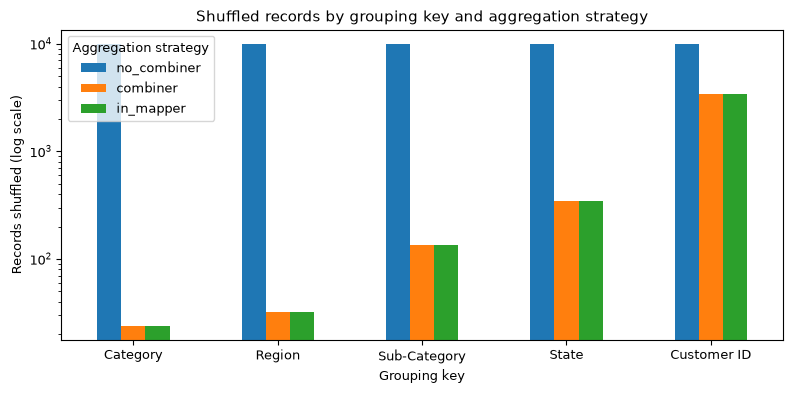

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_data = results_df.pivot(index="key", columns="mode", values="shuffled_records").loc[keys, modes]
plot_data.plot(kind="bar", ax=ax, logy=True)
ax.set(title="Shuffled records by grouping key and aggregation strategy",
       ylabel="Records shuffled (log scale)", xlabel="Grouping key")
ax.legend(title="Aggregation strategy")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("fig_shuffle_records.png", dpi=200, bbox_inches="tight")
plt.show()

## Figure 2 - scalability

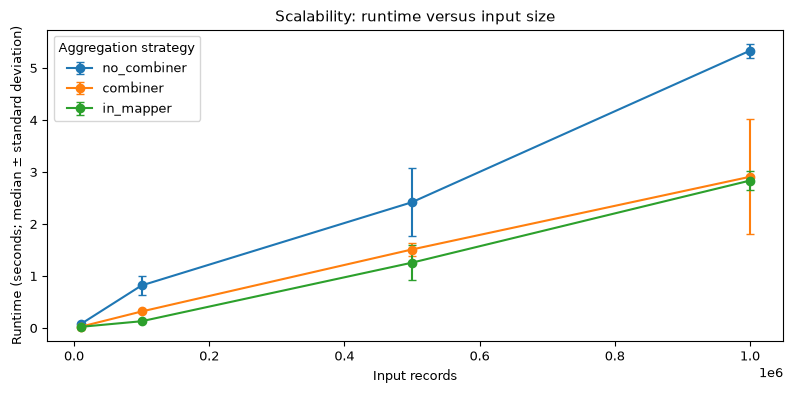

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for mode in modes:
    sub = scalability_df[scalability_df["mode"] == mode].sort_values("records")
    ax.errorbar(sub.records, sub.runtime_median_s, yerr=sub.runtime_std_s,
                marker="o", capsize=3, label=mode)
ax.set(title="Scalability: runtime versus input size",
       xlabel="Input records", ylabel="Runtime (seconds; median ± standard deviation)")
ax.legend(title="Aggregation strategy")
plt.tight_layout(); plt.savefig("fig_scalability.png", dpi=200, bbox_inches="tight")
plt.show()

## Figure 3 - state skew

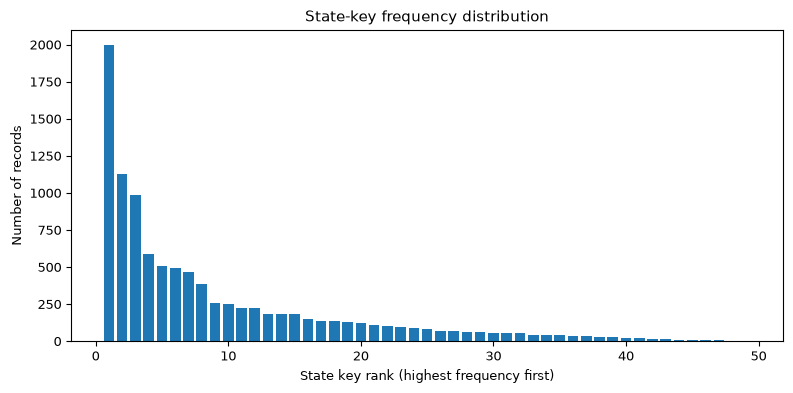

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
freq = sorted(skew_counts["State"].values(), reverse=True)
ax.bar(range(1, len(freq) + 1), freq)
ax.set(title="State-key frequency distribution",
       xlabel="State key rank (highest frequency first)", ylabel="Number of records")
plt.tight_layout(); plt.savefig("fig_state_skew.png", dpi=200, bbox_inches="tight")
plt.show()


## Experiment 4 – Reducer load distribution
Compare intermediate records assigned to each logical reducer for State aggregation. Load imbalance is diagnostic; it does not directly establish reducer processing time or stragglers.


mode,combiner,in_mapper,no_combiner
reducer,,,
Reducer 1,106,106,2483
Reducer 2,61,61,1277
Reducer 3,128,128,4776
Reducer 4,48,48,1458


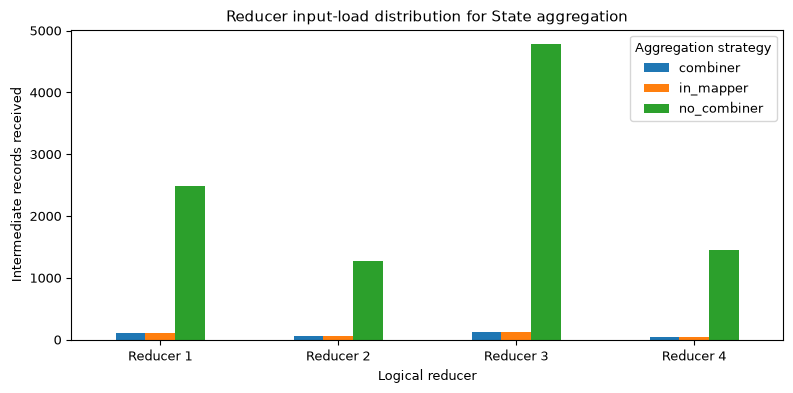

In [14]:
load_rows = []
for mode in modes:
    metric, _ = job(rows, "State", mode)
    for rid, load in enumerate(metric["reducer_loads"], 1):
        load_rows.append({"mode": mode, "reducer": f"Reducer {rid}", "input_records": load})
reducer_load_df = pd.DataFrame(load_rows)
reducer_load_df.to_csv("reducer_load_distribution.csv", index=False)
display(reducer_load_df.pivot(index="reducer", columns="mode", values="input_records"))

fig, ax = plt.subplots(figsize=(8, 4))
pivot = reducer_load_df.pivot(index="reducer", columns="mode", values="input_records")
pivot = pivot.reindex([f"Reducer {i}" for i in range(1, NUM_REDUCERS + 1)])
pivot.plot(kind="bar", ax=ax)
ax.set(title="Reducer input-load distribution for State aggregation",
       xlabel="Logical reducer", ylabel="Intermediate records received")
ax.legend(title="Aggregation strategy")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("fig_reducer_load.png", dpi=200, bbox_inches="tight")
plt.show()


## Experiment 5 – Aggregation efficiency comparison
Compare reductions in shuffled records and serialized shuffle bytes against the no-combiner baseline. Runtime is reported separately because it is also affected by local processing overhead.


,key,mode,record_reduction_pct,byte_reduction_pct,runtime_median_s,runtime_std_s
1,Category,combiner,99.760,99.610,0.030,0.013
2,Category,in_mapper,99.760,99.610,0.021,0.002
13,Customer ID,combiner,65.629,58.743,0.031,0.010
14,Customer ID,in_mapper,65.629,58.743,0.030,0.031
4,Region,combiner,99.680,99.399,0.033,0.004
5,Region,in_mapper,99.680,99.399,0.032,0.005
10,State,combiner,96.568,95.064,0.032,0.008
11,State,in_mapper,96.568,95.064,0.034,0.020
7,Sub-Category,combiner,98.639,97.754,0.037,0.041
8,Sub-Category,in_mapper,98.639,97.754,0.038,0.008


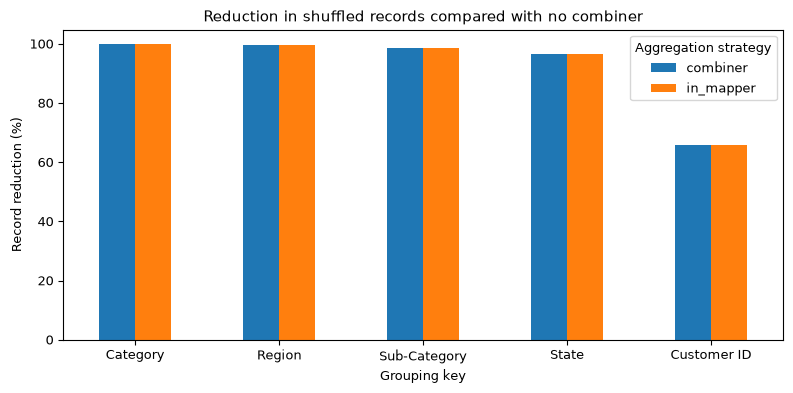

In [15]:
# Fixed: Use bracket notation to access the 'mode' column
efficiency_df = results_df[results_df["mode"] != "no_combiner"].copy()

efficiency_summary = efficiency_df[
    ["key", "mode", "record_reduction_pct", "byte_reduction_pct",
     "runtime_median_s", "runtime_std_s"]
].sort_values(["key", "mode"])

efficiency_summary.to_csv("aggregation_efficiency.csv", index=False)
display(efficiency_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ep = efficiency_summary.pivot(index="key", columns="mode",
                              values="record_reduction_pct").loc[keys]
ep.plot(kind="bar", ax=ax)
ax.set(title="Reduction in shuffled records compared with no combiner",
       xlabel="Grouping key", ylabel="Record reduction (%)")
ax.legend(title="Aggregation strategy")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("fig_aggregation_efficiency.png", dpi=200, bbox_inches="tight")
plt.show()


## Summary, interpretation, and limitations

- No combiner sends mapper output records directly to shuffle.
- Conventional combining and in-mapper combining aggregate locally before shuffle.
- The benefit depends on repeated grouping keys within mapper partitions.
- Record reduction and serialized-byte reduction are distinct measurements.
- Runtime is summarized using median and standard deviation over repeated runs.
- Scalability inputs are made by replicating the original dataset; this does not test independently sampled data.
- Reducer input counts diagnose distribution imbalance but do not prove stragglers.
- This local Python simulation does not measure Hadoop/Spark cluster execution, actual network traffic, or distributed fault tolerance.

**Generated outputs:** CSV result files and PNG figures are saved in the notebook's working directory.

**Conclusion:** The practical compares three MapReduce-style aggregation strategies on Sample Superstore, evaluates shuffle volume, runtime, scalability, key skew, and reducer load, and validates aggregates against Pandas `groupby`. Conclusions are limited to the tested local simulation.
